In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from gcnn_p4.layer_p4 import Z2P4GConv2d
from gcnn_p4.max_pool_p4 import GConv2d_MaxPooling

# This is the model that we are going to train:
class P4GConvNet(nn.Module):

    def __init__(self):

        super(P4GConvNet, self).__init__()
        # self.batck_size = batch_size
        self.gconv1 = Z2P4GConv2d(in_channels=1, out_channels=20, kernel_size=3)
        self.gconv2 = Z2P4GConv2d(in_channels=20, out_channels=20, kernel_size=3)
        self.fc     = nn.Linear(20 * 7 * 7, 10)

    def forward(self, x):

        x = F.relu(self.gconv1(x))
        x = GConv2d_MaxPooling(x, 2)

        x = F.relu(self.gconv2(x))
        x = GConv2d_MaxPooling(x, 2)

        x = x.view(x.size(0), x.size(1), x.size(2)*x.size(3))
        x = torch.sort(x, dim=2)[0]
        x = x.view(x.size(0), -1)

        x = F.dropout(x, training=self.training, p=0.1)
        x = self.fc(x)

        return F.log_softmax(x)
    
from torchinfo import summary

model = P4GConvNet()
summary(model, input_size=(1, 1, 28, 28))

C:\Users\miaoj\AppData\Local\Temp\ipykernel_58312\2300886921.py:33: UserWarning: Implicit dimension choice for log_softmax has been deprecated. Change the call to include dim=X as an argument.
  return F.log_softmax(x)


Layer (type:depth-idx)                   Output Shape              Param #
P4GConvNet                               [1, 10]                   --
├─Z2P4GConv2d: 1-1                       [1, 20, 4, 28, 28]        200
├─Z2P4GConv2d: 1-2                       [1, 20, 4, 14, 14]        3,620
├─Linear: 1-3                            [1, 10]                   9,810
Total params: 13,630
Trainable params: 13,630
Non-trainable params: 0
Total mult-adds (M): 3.48
Input size (MB): 0.00
Forward/backward pass size (MB): 0.63
Params size (MB): 0.05
Estimated Total Size (MB): 0.69

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from gcnn_p4.layer_p4 import Z2P4GConv2d
from gcnn_p4.max_pool_p4 import GConv2d_MaxPooling


class P4GConvNetScaled(nn.Module):
    """
    P4GConvNet with a width multiplier `k`.

    Parameters
    ----------
    k : int
        Number of output channels used by both G-Conv layers.
        Recommended 11 ≤ k ≤ 44  →  6 610 ≤ #params ≤ 34 450
    """
    def __init__(self, k: int = 20):
        super().__init__()
        self.k = k

        self.gconv1 = Z2P4GConv2d(in_channels=1, out_channels=k,  kernel_size=3)
        self.gconv2 = Z2P4GConv2d(in_channels=k, out_channels=k,  kernel_size=3)

        self.fc = nn.Linear(k * 7 * 7, 10)

    def forward(self, x):
        x = F.relu(self.gconv1(x))
        x = GConv2d_MaxPooling(x, 2)          # ↓ 14 × 14

        x = F.relu(self.gconv2(x))
        x = GConv2d_MaxPooling(x, 2)          # ↓ 7 × 7

        # sort-pooling
        b, c, h, w = x.shape
        x = x.view(b, c, h * w)
        x = torch.sort(x, dim=2)[0]
        x = x.view(b, -1)

        x = F.dropout(x, p=0.1, training=self.training)
        x = self.fc(x)
        return F.log_softmax(x, dim=1)  

if __name__ == "__main__":
    from torchinfo import summary
    for k in [11, 15, 20, 30, 40, 110]:
        model = P4GConvNetScaled(k)
        print(f"k = {k:2d}  →  parameters = {sum(p.numel() for p in model.parameters()):,}")
        summary(model, input_size=(1, 1, 28, 28))


k = 11  →  parameters = 6,610
k = 15  →  parameters = 9,550
k = 20  →  parameters = 13,630
k = 30  →  parameters = 23,140
k = 40  →  parameters = 34,450
k = 110  →  parameters = 164,020


In [8]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from gcnn_p4.network import P4GConvNet
import matplotlib.pyplot as plt
import torch.optim as optim
import torch.nn.functional as F

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

from gcnn_p4.network import P4GConvNet, CNN

k_list = [k for k in range(11, 110)]
parameters_list = []
acc_list = []

for k in k_list:

    digits = load_digits()
    X = digits.images  # shape = (n_samples, 8, 8)
    y = digits.target  # shape = (n_samples, )

    X = X / 16.0
    
    X = torch.FloatTensor(X).unsqueeze(1)  # (n_samples, 1, 8, 8)
    y = torch.LongTensor(y)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    def upscale_to_mnist_size(batch_x):
        return F.interpolate(batch_x, size=(28, 28), mode='bilinear', align_corners=False)

    train_ds = TensorDataset(X_train, y_train)
    test_ds  = TensorDataset(X_test,  y_test)

    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
    test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)

    model = P4GConvNetScaled(k=k)

    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    parameters_list.append(total_params)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    num_epochs = 64

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # Upscale to 28x28
            batch_x = upscale_to_mnist_size(batch_x)

            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = F.nll_loss(outputs, batch_y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * batch_x.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                batch_x = upscale_to_mnist_size(batch_x)

                outputs = model(batch_x)
                _, predicted = torch.max(outputs, 1)
                total += batch_y.size(0)
                correct += (predicted == batch_y).sum().item()

        accuracy = 100.0 * correct / total
        print(f"k={k} Epoch [{epoch+1}/{num_epochs}] - Loss: {epoch_loss:.4f} - Test Accuracy: {accuracy:.2f}%")
    
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            batch_x = upscale_to_mnist_size(batch_x)

            outputs = model(batch_x)
            _, predicted = torch.max(outputs, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    accuracy = 100.0 * correct / total
    acc_list.append(accuracy)

    with open('results.txt', 'w') as f:
        for p, a in zip(parameters_list, acc_list):
            f.write(f"{p},{a}\n")

k=11 Epoch [1/64] - Loss: 9.1437 - Test Accuracy: 12.50%
k=11 Epoch [2/64] - Loss: 5.0012 - Test Accuracy: 26.67%
k=11 Epoch [3/64] - Loss: 4.1105 - Test Accuracy: 28.61%
k=11 Epoch [4/64] - Loss: 3.6679 - Test Accuracy: 35.28%
k=11 Epoch [5/64] - Loss: 3.0738 - Test Accuracy: 43.61%
k=11 Epoch [6/64] - Loss: 2.8710 - Test Accuracy: 42.50%
k=11 Epoch [7/64] - Loss: 2.6795 - Test Accuracy: 42.78%
k=11 Epoch [8/64] - Loss: 2.3856 - Test Accuracy: 42.78%
k=11 Epoch [9/64] - Loss: 2.1978 - Test Accuracy: 47.78%
k=11 Epoch [10/64] - Loss: 2.0940 - Test Accuracy: 51.11%
k=11 Epoch [11/64] - Loss: 1.8540 - Test Accuracy: 59.72%
k=11 Epoch [12/64] - Loss: 1.7600 - Test Accuracy: 60.83%
k=11 Epoch [13/64] - Loss: 1.6589 - Test Accuracy: 59.17%
k=11 Epoch [14/64] - Loss: 1.5661 - Test Accuracy: 60.56%
k=11 Epoch [15/64] - Loss: 1.5441 - Test Accuracy: 63.06%
k=11 Epoch [16/64] - Loss: 1.4292 - Test Accuracy: 64.44%
k=11 Epoch [17/64] - Loss: 1.3940 - Test Accuracy: 63.89%
k=11 Epoch [18/64] - Lo

C:\Users\miaoj\AppData\Local\Temp\ipykernel_108448\4085086353.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


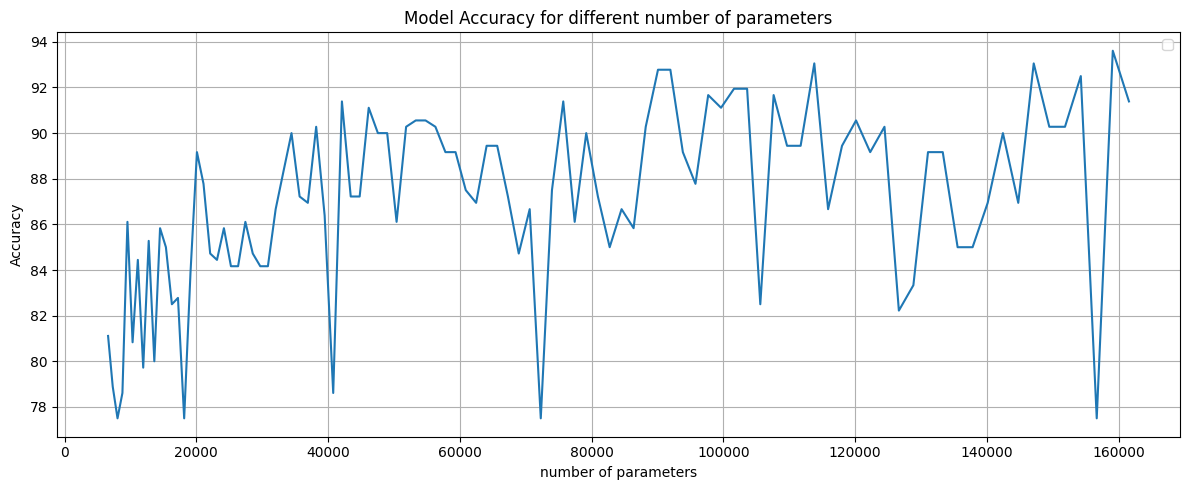

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(parameters_list, acc_list)
plt.xlabel('number of parameters')
plt.ylabel('Accuracy')
plt.title('Model Accuracy for different number of parameters')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [10]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

from gcnn_p4.network import P4GConvNet, CNN

class DigitsDataset(Dataset):
    """Wraps (N,1,28,28) tensors and applies an optional transform per sample."""

    def __init__(self, images: torch.Tensor, labels: torch.Tensor, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[idx]

def make_test_loader(rotation_transform, batch_size: int = 64):
    """Return DataLoader over the *test* split with the requested rotation."""

    # Load & normalise digits to [0,1]
    digits = load_digits()
    X = torch.FloatTensor(digits.images / 16.0).unsqueeze(1)  # (N,1,8,8)
    y = torch.LongTensor(digits.target)

    # Re‑produce the same 80/20 split used during training
    _, X_test, _, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Upscale from 8×8 → 28×28 to fit the network (which expects MNIST‑sized inputs)
    X_test = F.interpolate(X_test, size=(28, 28), mode="bilinear", align_corners=False)

    dataset = DigitsDataset(X_test, y_test, transform=rotation_transform)
    return DataLoader(dataset, batch_size=batch_size, shuffle=False)

# -----------------------------------------------------------------------------
# Evaluation helper
# -----------------------------------------------------------------------------

def evaluate(model, loader: DataLoader):
    model = model.to(device)
    model.eval()

    correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    acc = 100.0 * correct / total
    return acc

In [12]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from gcnn_p4.network import P4GConvNet
import matplotlib.pyplot as plt
import torch.optim as optim
import torch.nn.functional as F

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

from gcnn_p4.network import P4GConvNet, CNN

k_list = [k for k in range(11, 110)]
parameters_list = []
acc_list = []

# Random rotation in [‑90°, +90°]
transform_rand = transforms.RandomRotation(degrees=90)

loader_rand = make_test_loader(transform_rand)

for k in k_list:

    digits = load_digits()
    X = digits.images  # shape = (n_samples, 8, 8)
    y = digits.target  # shape = (n_samples, )

    X = X / 16.0
    
    X = torch.FloatTensor(X).unsqueeze(1)  # (n_samples, 1, 8, 8)
    y = torch.LongTensor(y)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    def upscale_to_mnist_size(batch_x):
        return F.interpolate(batch_x, size=(28, 28), mode='bilinear', align_corners=False)

    train_ds = TensorDataset(X_train, y_train)
    test_ds  = TensorDataset(X_test,  y_test)

    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
    test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)

    model = P4GConvNetScaled(k=k)

    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    parameters_list.append(total_params)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    num_epochs = 64

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # Upscale to 28x28
            batch_x = upscale_to_mnist_size(batch_x)

            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = F.nll_loss(outputs, batch_y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * batch_x.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                batch_x = upscale_to_mnist_size(batch_x)

                outputs = model(batch_x)
                _, predicted = torch.max(outputs, 1)
                total += batch_y.size(0)
                correct += (predicted == batch_y).sum().item()

        accuracy = 100.0 * correct / total
        print(f"k={k} Epoch [{epoch+1}/{num_epochs}] - Loss: {epoch_loss:.4f} - Test Accuracy: {accuracy:.2f}%")

    acc = evaluate(
        model,
        loader_rand,
    )

    acc_list.append(acc)

    with open('results_random.txt', 'w') as f:
        for p, a in zip(parameters_list, acc_list):
            f.write(f"{p},{a}\n")

k=11 Epoch [1/64] - Loss: 6.7985 - Test Accuracy: 24.17%
k=11 Epoch [2/64] - Loss: 4.3303 - Test Accuracy: 36.94%
k=11 Epoch [3/64] - Loss: 3.6805 - Test Accuracy: 31.94%
k=11 Epoch [4/64] - Loss: 3.1787 - Test Accuracy: 42.50%
k=11 Epoch [5/64] - Loss: 2.7862 - Test Accuracy: 40.28%
k=11 Epoch [6/64] - Loss: 2.5683 - Test Accuracy: 37.22%
k=11 Epoch [7/64] - Loss: 2.3615 - Test Accuracy: 47.22%
k=11 Epoch [8/64] - Loss: 2.1908 - Test Accuracy: 46.11%
k=11 Epoch [9/64] - Loss: 2.0294 - Test Accuracy: 51.39%
k=11 Epoch [10/64] - Loss: 1.8870 - Test Accuracy: 49.72%
k=11 Epoch [11/64] - Loss: 1.8456 - Test Accuracy: 58.33%
k=11 Epoch [12/64] - Loss: 1.6510 - Test Accuracy: 57.22%
k=11 Epoch [13/64] - Loss: 1.6017 - Test Accuracy: 57.78%
k=11 Epoch [14/64] - Loss: 1.5908 - Test Accuracy: 58.61%
k=11 Epoch [15/64] - Loss: 1.5201 - Test Accuracy: 52.50%
k=11 Epoch [16/64] - Loss: 1.4612 - Test Accuracy: 55.00%
k=11 Epoch [17/64] - Loss: 1.4395 - Test Accuracy: 58.61%
k=11 Epoch [18/64] - Lo

C:\Users\miaoj\AppData\Local\Temp\ipykernel_108448\4085086353.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


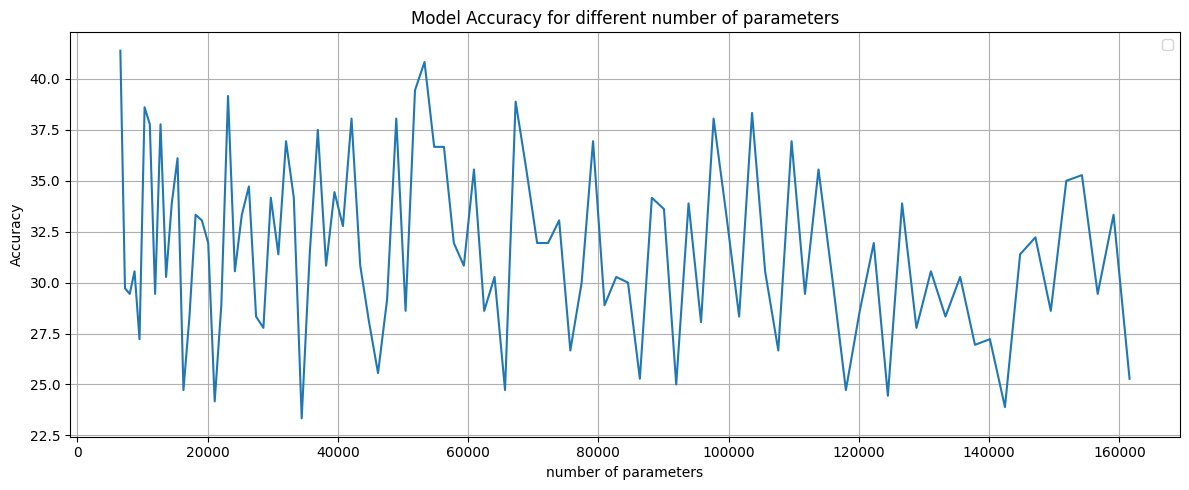

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(parameters_list, acc_list)
plt.xlabel('number of parameters')
plt.ylabel('Accuracy')
plt.title('Model Accuracy for different number of parameters')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()